# Tutorial de Ciencia de Datos (UdeSA) 2026
## Tutorial 8
### Clasificacion: Logit, KNN y Metricas de Precisión


**Objetivo:** entender la "diferencia" entre clasificación y regresión. Utilizar logit y KNN. Análisis de la curva ROC.

Veremos:
- Clasificación
- Medidas de precisión
- Curva de ROC
- Logit
- KNN


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn import datasets
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, recall_score
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay
#from sklearn.metrics import plot_roc_curve
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import make_blobs
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

#### Nueva situación: 'y' es una variable cualitativa. ¿Qué hacer?

- ¿Por qué en el caso de 'y' cualitativa la regresión linear no es una opción apropiada?

1. Puede no haber una forma de transformar una variable cualitativa con más de 2 niveles en una variable cuantitaiva que nos 'sirva' para una regresión lineal: puede que 'y' no tenga un orden. Por ejemplo, si la 'y' hace referencia a enfermedades. ¿Cómo asignarles un valor? Implicaría asumir un orden y también que la diferencia entre las enfermedades es equivalente...

2. En el caso binario (2 niveles) podemos transformar la variable a una variable numérica. Por ejemplo: y=1 pobre e y=0 no pobre. Sin embargo, con una regresión  lineal podría ocurrir que generemos predicciones fuera del intervalo [0, 1] y por ende no podremos interpretarlo como probabilidades...

Entonces...
#### Vamos a clasificar 'y' (variable cualitativa) en base a 'x'

- ¿Estamos ante un caso de aprendizaje supervisado o no supervisado?

Vamos a trabajar con bases donde tenemos el output esperado. Por lo tanto, nuestros modelos serán casos de aprendizaje supervisado.
     
- ¿Qué es el clasificador de Bayes?

Clasificar según el estado más probable minimiza el riesgo esperado. Por ej: si la probabilidad de que una persona me pague un credito es mayor que 0.5, predigo que pagará el credito.

#### Modelos:
    
1. Regresión logística
2. Análisis de discriminante lineal
3. KNN

Vamos a construir un clasificador con los datos de training. Queremos que funcione bien no solo en el conjunto de entrenamiento sino también en el conjunto de test.

#### REGRESIÓN LOGÍSTICA CON SCIKIT-LEARN

Algoritmo de clasificación que se usa para predecir la probabilidad de una variable dependiente categórica. El modelo logit predice $P(Y=1)$ como una función de $X$. Se modela la probabilidad de una forma tal que los outputs serán valores entre 0 y 1 para cualquier valor de $X$.

$$log(\frac{p(x)}{1-p(x)}) = β_0 + β_1x $$

##### Interpretación de los coeficientes

El efecto de $β_1$ es constante solo sobre el logaritmo de las chances, no sobre la probabilidad final. En este sentido, **una unidad adicional en $x$ se asocia en promedio a un cambio de $β_1$ en el logaritmo de las chances de que ocurra (manteniendo el resto constante)**. Por ello, para interpretarlo en terminos de las chances, tenemos que decir que **un aumento de una unidad en $x$ multiplica las chances por $e^{β_1}$**

Para llevar el modelo abstracto de los logaritmos a uno de probabilidad, simplemente tenemos que despejar la función original hasta obtener:
$$ p(x) = \frac{e^{β_0 + β_1x}}{1 + e^{β_0 + β_1x}}$$

Ahora utilizaremos la función [LogisticRegression()](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

Se pueden proveer muchos parámetros opcionales para esta función:

- **fit_intercept**: Boolean que decide si calcular el intercepto (True) o considerarlo igual a cero (False). Por default es True.
- **penalty**: Se determina se usar algún tipo de regularización. Posibles valores: ‘l1’, ‘l2’, ‘elasticnet’. El valor por defecto es default es ‘l2’, es decir que se aplica regularización (Ridge). El parámetro **C** regula su intensidad.


In [2]:
# Creamos un vector de x e y para fines del ejemplo.
np.random.seed(25)
X = np.random.normal(size=100)
print(X)

# Recordatorio: para la regresión lineal creamos un vector aleatorio así:
# y = 2 + 3*x + np.random.rand(50, 1)
# Ahora lo crearemos de la siguiente forma para que tenga más sentido usar una regresión logística
y = (X > 0).astype(float) # si no pusiera astype sería un array de True y False

# Alteramos los valores de X y sumamos variación con el "error"
X[X > 0] *= 4
X += .5 * np.random.normal(size=100)
X = X.reshape((-1, 1)) # para tenerlo como columna
#print(X)

[ 0.22827309  1.0268903  -0.83958485 -0.59118152 -0.9568883  -0.22232569
 -0.61991511  1.83790458 -2.05323076  0.86858305 -0.92073444 -0.23231186
  2.1529569  -1.33466147  0.07637965 -1.24608928  1.20227231 -1.04994158
  1.05661011 -0.41967767  2.29484234 -2.59448738  2.8227564   0.68088892
 -1.57769345 -1.97625359  0.53333982 -0.29086971 -0.51351967  1.98262608
  0.22600105 -1.83990496  1.60767083  0.38829194  0.39973206  0.4054766
  0.21700177 -0.6334391   0.24662153 -1.93954552  0.11405963 -1.8853414
  0.24308048 -0.70548067  0.36462762 -0.50295216 -0.22575155 -0.56553773
  0.10339501  2.01840842  1.09424827  1.6624344  -0.62745348  1.62119964
  1.17813267 -0.37487875 -0.54432898  0.28776118 -0.20581999  1.18998786
  0.72892688 -0.22204012 -1.62270578  0.31254055 -1.16042141  0.31355968
  0.47199786  0.57786171  0.50540675 -0.62648777 -0.34636933 -2.06594183
  0.76893629  1.12886631  0.16692354 -0.96725539  0.49199625 -0.55085717
 -0.08469407  1.96756834 -0.06267511 -0.85113578  0.4

Text(0, 0.5, 'Y')

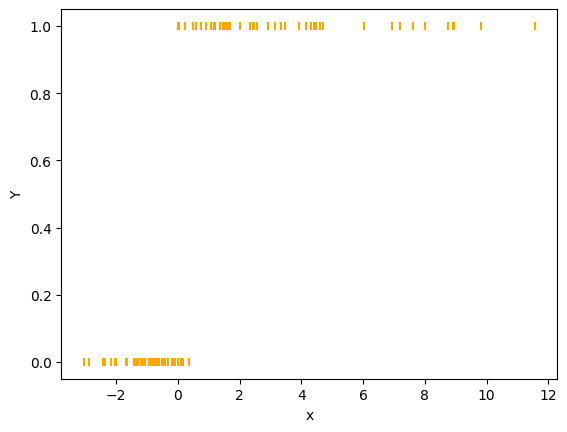

In [3]:
# Graficamos para ver si nos quedó un vector que 1s y 0s
plt.scatter(X, y, color='orange', zorder=20, marker="|")
plt.xlabel('x')
plt.ylabel('Y')

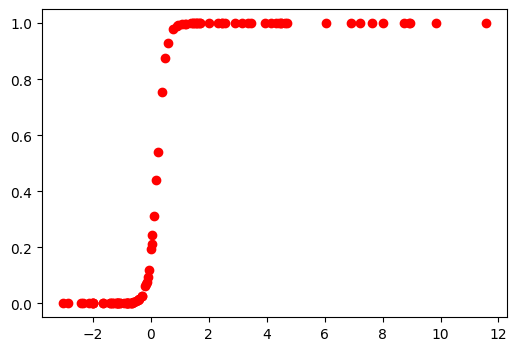

In [4]:
# Ajustamos el clasificador con el método fit()
log_reg = LogisticRegression(C=np.inf).fit(X, y)

# Predicciones (probabilidad)
y_pred_score = log_reg.predict_proba(X)[:,1]   # Por qué seleccionamos la columna 1?

# Gráfico de resultados
plt.figure(figsize=(6, 4))
plt.scatter(X, y_pred_score, color='red', zorder=20)
plt.show()

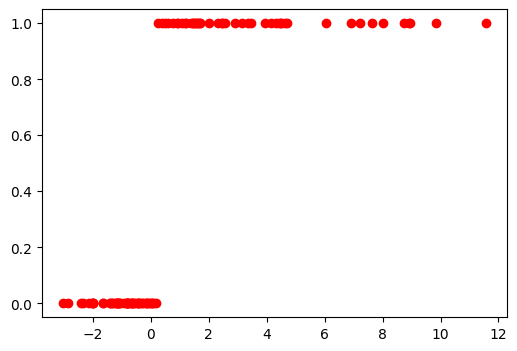

In [5]:
# Convertimos las probabilidades en Y con valores 1 o 0 (usando el clasificador de Bayes)
y_pred = np.where(y_pred_score > 0.5, 1, y_pred_score)
y_pred = np.where(y_pred_score <= 0.5, 0, y_pred)

#Equivalente: y_pred = log_reg.predict(X)

plt.figure(figsize=(6, 4))
plt.scatter(X, y_pred, color='red', zorder=20)
plt.show()

**Punto de corte:** También podemos decidir/buscar el umbral de probabilidad a partir del cual nuestro clasificador deja de considerar a una observación como 0 (o negativo) y la considera como 1 (positivo).

$$ p(x) = \frac{e^{β_0 + β_1x}}{1 + e^{β_0 + β_1x}}$$

En particular, esto sucede cuando:

$$
X^* = -\frac{\beta_0}{\beta_1} \qquad \text{con cut-off en }p = 0,5
$$

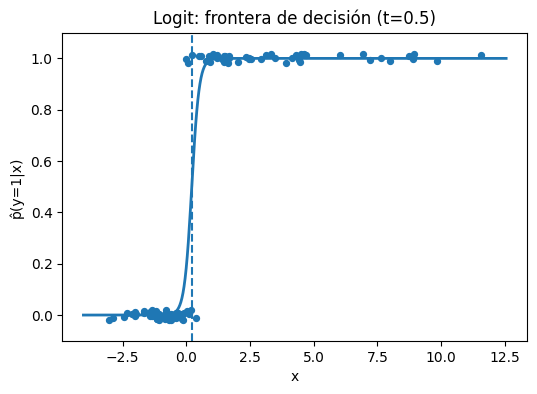

In [6]:
beta0 = log_reg.intercept_[0]
beta1 = log_reg.coef_[0, 0]

x_grid = np.linspace(X.min() - 1, X.max() + 1, 400).reshape(-1, 1)
p_grid = log_reg.predict_proba(x_grid)[:, 1]
x_star = -beta0 / beta1  # frontera para t=0.5

# Jitter para ver mejor los 0/1 en el scatter
jitter = (np.random.rand(len(y)) - 0.5) * 0.04

plt.figure(figsize=(6,4))
plt.scatter(X.ravel(), y + jitter, s=18, zorder=2)
plt.plot(x_grid, p_grid, linewidth=2, zorder=3)
plt.axvline(x_star, linestyle="--", linewidth=1.5, zorder=1)
plt.ylim(-0.1, 1.1)
plt.xlabel("x"); plt.ylabel("p̂(y=1|x)")
plt.title("Logit: frontera de decisión (t=0.5)")
plt.show()

In [ ]:
plt.figure(figsize=(6,4))
plt.hist(X[y==0].ravel(), bins=20, alpha=0.6, density=True, label="y=0")
plt.hist(X[y==1].ravel(), bins=20, alpha=0.6, density=True, label="y=1")
plt.axvline(x_star, linestyle="--", linewidth=1.5, label="frontera t=0.5")
plt.xlabel("x"); plt.ylabel("densidad"); plt.legend()
plt.title("Separación de clases en X")
plt.show()

### Medidas de precisión

Dependiendo la prioridad del problema seguramente vamos a querer usar diferentes métricas. Scikit learn tiene muchas métricas que pueden explorar en el módulo [metrics](https://scikit-learn.org/stable/modules/model_evaluation.html)

- Sensibilidad (sensitivity)= VP / (VP + FN)
- Especificidad (specificity)= VN / (VN + FP)
- False Positive Rate = FP/N
- False Negative Rate = FN/P
- Precision (Positive Predicted Value) = VP / (VP + FP)
- Accuracy= (VP + VN) / total

Nota: Cuidado con las traducciones! "Accuracy" lo pueden encontrar traducido como "precisión" y eso puede generar confusión con la medida "precision" (o positive predicted value). Mi sugerencia es traducir "accuracy" como "exactitud".


[Matriz de confusión](https://www.unite.ai/what-is-a-confusion-matrix/)
<center>
<img src="https://www.unite.ai/wp-content/uploads/2019/12/Preventive_Medicine-e1576294312614.png" width="1000">

</center>

La matriz de confusión de sklearn pone en las filas las Y reales y las columnas las Y predichas. Muestra así los valores:

                               predicción
                         real   tn fp
                                fn tp

In [ ]:
matriz_confusion = confusion_matrix(y, y_pred)

print('Confusion Matrix:')
print(matriz_confusion)
print('Accuracy Score:', accuracy_score(y, y_pred))

# Nota importante: en Python la matriz de confusión tiene:
# en las filas los valores ciertos
# y en las columnas los valores predichos

In [ ]:
# Para los casos donde la predición (la y) es binaria podemos usar lo siguiente:
tn, fp , fn, tp = confusion_matrix(y, y_pred).ravel()   # Ravel transforma la matriz en un 1D array
# equivalente a: [tn, fp] , [fn, tp] = confusion_matrix(y, y_pred_2)

print("Verdadero 0: ", tn)
print("Falso 1: ", fp)
print("Falso 0: ", fn)
print("Verdadero 1: ", tp)

In [ ]:
# accuracy: (tp + tn) / (p + n)
accuracy = accuracy_score(y, y_pred)
print('Accuracy: %f' % accuracy)

# sensitivity: tp / p = tp / (tp + fn)
sensitivity = recall_score(y, y_pred)
print('Recall: %f' % recall)

### Curva ROC                  
ROC: Receiver Operating Characteristics. Es un gráfico que evalua el rendimiento de un modelo de clasificación probando todos los umbrales de desición posibles al mismo tiempo. Mapea el trade-off completo entre aciertos y errores a medida que desplazamos la frontera (de 0 a 1).

Se construye a partir de dos ejes:

*   Eje Y (Tasa de Verdaderos Positivos / Sensibilidad)
*   Eje X (Tasa de Falsos Postiviso / 1 - Especificidad)

AUC: Area Under Curve. Cuantifica el rendimiento global de un modelo de clasificación al medir el área bidimensional situada por debajo de la curva ROC. Esto facilita comparaciones idrectas entre distintos modelos. Los valores pueden ir de 0 a 1:

* $AUC < 0.5$: Modelo con error sistematico.
* $AUC = 0.5$: Capacidad nula de discriminacion (igual al azar).
* $0.7 \le AUC < 0.8$: Nivel aceptable.
* $0.8 \le AUC < 0.9$: Nivel excelente.
* $AUC = 1$: Clasificación perfecta.

Como se veria este modelo perfecto en el grafico?

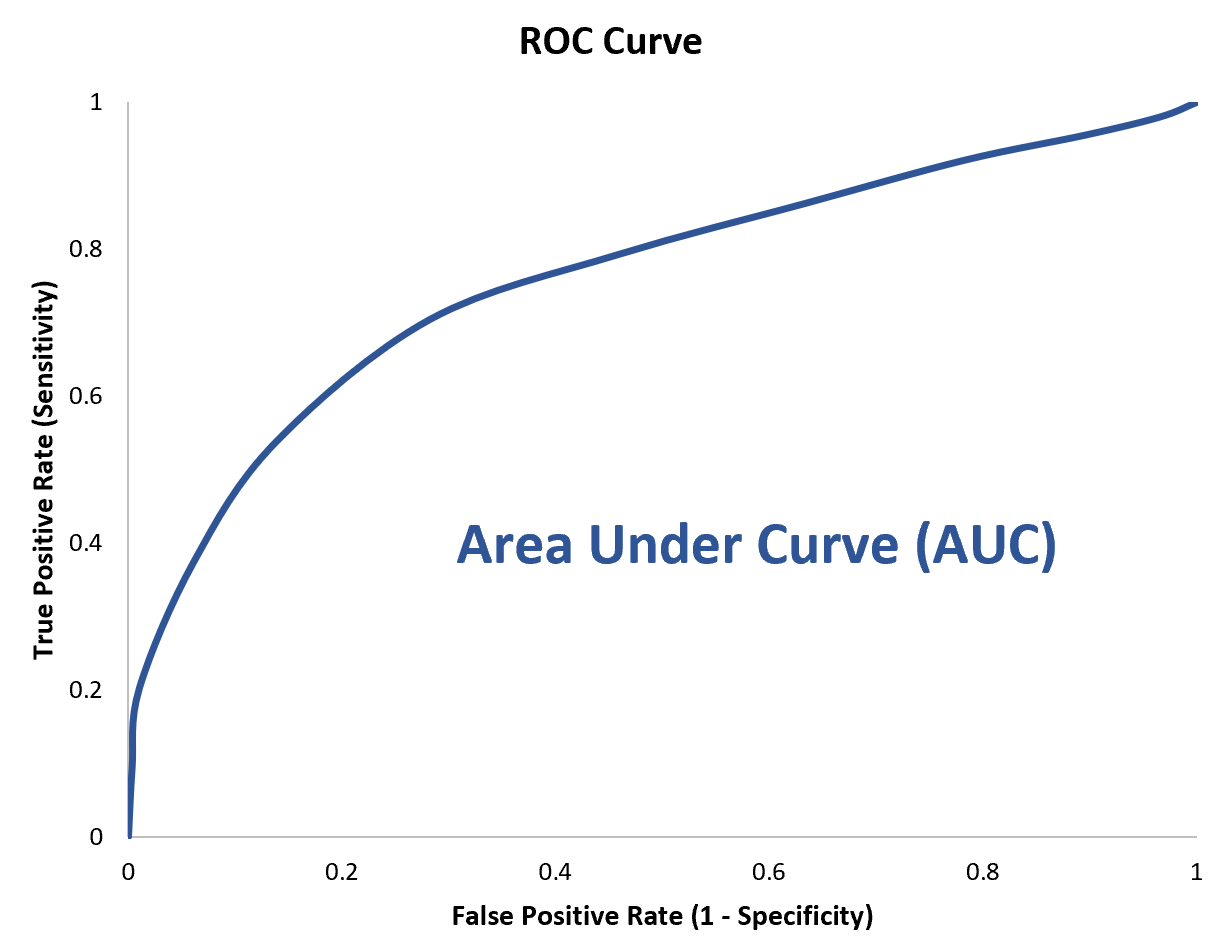

Veremos como utilizar las funciones:

-  [roc_curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html#sklearn.metrics.roc_curve): computa la curva de ROC
- [roc_auc_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html#sklearn.metrics.roc_auc_score): Computa el area bajo la curva de ROC de los scores predichos.
- [RocCurveDisplay](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay): Sirve para visualizar la curva de ROC. Con el mismo fin existe [plot_roc_curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.plot_roc_curve.html#sklearn.metrics.plot_roc_curve)

In [7]:
auc = roc_auc_score(y, y_pred_score)
print('AUC: %.3f' % auc)

AUC: 0.997


In [8]:
fpr, tpr, thresholds = roc_curve(y, y_pred_score)

tabla_roc = pd.DataFrame({
    'Threshold': thresholds,
    'FPR': fpr,
    'TPR': tpr
})

display(tabla_roc.round(3))

,Threshold,FPR,TPR
0,inf,0.000,0.000
1,1.000,0.000,0.213
2,0.875,0.000,0.936
3,0.754,0.019,0.936
4,0.541,0.019,0.957
5,0.313,0.057,0.957
6,0.245,0.057,0.979
7,0.211,0.075,0.979
8,0.192,0.075,1.000
9,0.000,1.000,1.000


Scikit-learn agrega un umbral inicial igual a infinito (inf) para representar el caso en que todas las observaciones se clasifican como negativas. Esto permite que la curva ROC comience en el punto (0,0). Este umbral es artificial y no representa una probabilidad.

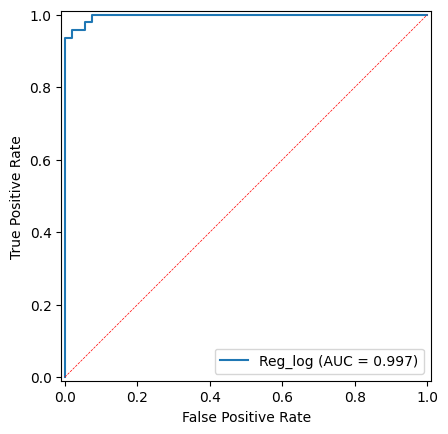

In [10]:
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=auc)
display.plot()

plt.legend([f'Reg_log (AUC = {auc:.3f})'])
plt.plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=.5)
plt.show()

#### Repitamos el ejercicio partiendo la base en train y test

In [ ]:
# Entrenaremos con el 70% de la base de datos y el resto se usarán para testear
# el modelo obtenido
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)


In [ ]:
# Estimo:
# Ajustamos el clasificador con el método fit()
log_reg = LogisticRegression(C=np.inf).fit(X_train, y_train)

y_test_pred_score = log_reg.predict_proba(X_test)[:,1]
y_test_pred = log_reg.predict(X_test)



In [ ]:
# AUC y ROC
from IPython.display import display
auc = roc_auc_score(y_test, y_test_pred_score)
print('AUC: %.4f' % auc)

fpr, tpr, thresholds = roc_curve(
    y_test, y_test_pred_score, drop_intermediate=False
)

# Creamos una tabla ordenada
tabla_roc = pd.DataFrame({
    'Threshold': thresholds,
    'FPR': fpr,
    'TPR': tpr
})

display(tabla_roc.round(4))


In [ ]:
roc_display = RocCurveDisplay(
    fpr=fpr,
    tpr=tpr,
    roc_auc=auc,
    name='Reg_log'
)

roc_display.plot()
plt.legend([f'Reg_log (AUC = {auc:.4f})'])
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.show()


## K-Nearest Neighbors (KNN): idea y por qué es no paramétrico

Qué es  
KNN es un método simple de aprendizaje por instancias: para predecir la clase de un punto nuevo x*, busca sus K vecinos más cercanos en el set de entrenamiento y decide por mayoría (clasificación) o por promedio (regresión).

Regla básica  
1. Elegimos una métrica de distancia para ver qué observaciones están más cerca (euclídea por defecto).  
2. Elegimos un K.  
3. Tomamos los K puntos de entrenamiento más cercanos a x*.  
4. Clasificación: votan las clases de esos K vecinos.

No hace supuestos de distribución  
- No asume normalidad, linealidad ni forma funcional.  
- La frontera de decisión se adapta a los datos localmente.  
- Por eso KNN es no paramétrico: no estima un conjunto fijo de parámetros globales como en logit; “aprende” guardando los datos y usando distancias.

Hiperparámetros clave  
- K: chico → modelo muy flexible, puede sobreajustar; grande → más suave, puede subajustar.  
- Distancia: euclídea, Manhattan, Minkowski, etc.  
- Ponderación: todos los vecinos valen igual o se pondera por 1/distancia.

Consideraciones prácticas  
- Escalado: imprescindible si las variables están en escalas distintas.  
- Dimensionalidad: con muchas variables las distancias pierden contraste (curse of dimensionality). A medida que agregamos dimensiones, las observaciones tienden a quedar más dispersas y las distancias entre vecinos cercanos y lejanos pueden volverse relativamente parecidas. Se dificulta identificar quién es realmente un vecino cercano.  
- Costo computacional: predecir puede ser costoso si el dataset es grande, porque hay que buscar vecinos.



In [ ]:
# Reproducibilidad
RANDOM_STATE = 42

# Generamos dos clústers con algo de superposición
X, y = make_blobs(
    n_samples=300,
    centers=[(-2, 0), (2, 0)],
    cluster_std=[1.2, 1.2],
    n_features=2,
    random_state=RANDOM_STATE
)

# (Opcional) pequeña rotación para que no quede perfectamente horizontal
theta = np.deg2rad(20)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])
X = X @ R.T

# Armamos un DataFrame por si querés mirarlo
df = pd.DataFrame(X, columns=["x1", "x2"])
df["y"] = y

# Gráfico 2D coloreado por la clase y
plt.figure(figsize=(6, 5))
scatter = plt.scatter(df["x1"], df["x2"], c=df["y"], s=35)
plt.xlabel("x1")
plt.ylabel("x2")
handles, _ = scatter.legend_elements()
plt.legend(handles, ["Clase 0", "Clase 1"], loc="best")
plt.show()

In [ ]:
# Usamos X, y del bloque anterior
X_arr = X  # (n,2)
y_arr = y

# Escalado (muy importante para KNN)
scaler = StandardScaler().fit(X_arr)
X_scaled = scaler.transform(X_arr)

# Malla para pintar la frontera
h = 0.05
x_min, x_max = X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1
y_min, y_max = X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

Ks = [1, 5, 15]

fig, axes = plt.subplots(1, len(Ks), figsize=(5 * len(Ks), 4), constrained_layout=True)

# Colormaps (suaves)
cmap_bg = ListedColormap(["#ddeeff", "#ffe6e6"])
cmap_pts = ListedColormap(["#1f77b4", "#d62728"])

for ax, K in zip(axes, Ks):
    # Entrenar KNN
    knn = KNeighborsClassifier(n_neighbors=K, weights="uniform")
    knn.fit(X_scaled, y_arr)

    # Predicción sobre la malla
    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Fondo con la frontera
    ax.contourf(xx, yy, Z, alpha=0.8, cmap=cmap_bg, levels=[-0.5, 0.5, 1.5])

    # Puntos de entrenamiento (en el espacio escalado)
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_arr, cmap=cmap_pts, s=25, edgecolor="k", linewidth=0.3)

    ax.set_title(f"KNN con K = {K}")
    ax.set_xlabel("x1 (escalado)")
    ax.set_ylabel("x2 (escalado)")


plt.show()

Como K es un **hiperparámetro**, tenemos que elegirlo nosotros. Acá lo hacemos mediante validación cruzada.

In [ ]:
# Usamos X, y ya creados
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Ks = list(range(1, 32, 2))  # K impares para evitar empates
mean_scores = []
std_scores  = []

for K in Ks:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=K))
    ])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    mean_scores.append(scores.mean())
    std_scores.append(scores.std())

best_idx = int(np.argmax(mean_scores))
best_k = Ks[best_idx]
print(f"Mejor K por accuracy CV: {best_k} | accuracy CV media = {mean_scores[best_idx]:.3f}")

# Curva de validación
plt.figure(figsize=(6,4))
plt.plot(Ks, mean_scores, marker="o")
plt.fill_between(Ks,
                 np.array(mean_scores) - np.array(std_scores),
                 np.array(mean_scores) + np.array(std_scores),
                 alpha=0.2)
plt.xlabel("K vecinos")
plt.ylabel("Accuracy CV (media 5-fold)")
plt.title("Curva de validación para K en KNN")
plt.xticks(Ks)
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report,
                             roc_auc_score)
pipe_best = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k))
])

# Predicciones out-of-fold para evaluar de forma honesta
y_pred_oof = cross_val_predict(pipe_best, X, y, cv=cv, method="predict")
# Probabilidades para AUC (si querés ROC luego)
y_proba_oof = cross_val_predict(pipe_best, X, y, cv=cv, method="predict_proba")[:,1]

cm   = confusion_matrix(y, y_pred_oof, labels=[1,0])
acc  = accuracy_score(y, y_pred_oof)
prec = precision_score(y, y_pred_oof)
rec  = recall_score(y, y_pred_oof)
auc  = roc_auc_score(y, y_proba_oof)

print(f"K={best_k} | Acc={acc:.3f} | Prec={prec:.3f} | Recall={rec:.3f} |  AUC={auc:.3f}\n")

print("\nClassification report:")
print(classification_report(y, y_pred_oof, digits=3))

# y_true, y_pred_oof ya definidos
# Usá el orden estándar [0, 1] para evitar confusiones
cm = confusion_matrix(y, y_pred_oof, labels=[0, 1])

cm_df = pd.DataFrame(
    cm,
    index=pd.Index(["True 0 (negativo)", "True 1 (positivo)"], name="Real"),
    columns=pd.Index(["Pred 0 (negativo)", "Pred 1 (positivo)"], name="Predicho"),
)
cm_df